# BigMart Data Preparation

This notebook handles the preparation stage for the BigMart project.

The goal is to load `Train.csv` and `Test.csv`, explore the training data, clean both datasets in a consistent way, apply the same feature engineering, and save prepared files for modeling later.

## 1. Imports

Only the libraries needed for preparation and basic exploration are used here.

In [1]:
from pathlib import Path

import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load Train and Test Data

Both files are loaded here, but the main exploration is done on the training set because that is the dataset with the target column.

In [2]:
train_df = pd.read_csv("Train.csv")
test_df = pd.read_csv("Test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (8523, 12)
Test shape: (5681, 11)


In [3]:
train_df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 3. Quick Exploration of the Training Data

This section keeps the exploration simple and focused on what matters before cleaning.

In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [5]:
train_missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": (train_df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

train_missing

,missing_count,missing_percent
Outlet_Size,2410,28.28
Item_Weight,1463,17.17
Item_Fat_Content,0,0.00
Item_Identifier,0,0.00
Item_Visibility,0,0.00
Item_Type,0,0.00
Outlet_Identifier,0,0.00
Item_MRP,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Location_Type,0,0.00


In [6]:
train_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35
Item_Fat_Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item_Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_MRP,8523.0,NaN,NaN,NaN,140.992782,62.275067,31.29,93.8265,143.0128,185.6437,266.8884
Outlet_Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Establishment_Year,8523.0,NaN,NaN,NaN,1997.831867,8.37176,1985.0,1987.0,1999.0,2004.0,2009.0
Outlet_Size,6113,3,Medium,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Location_Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


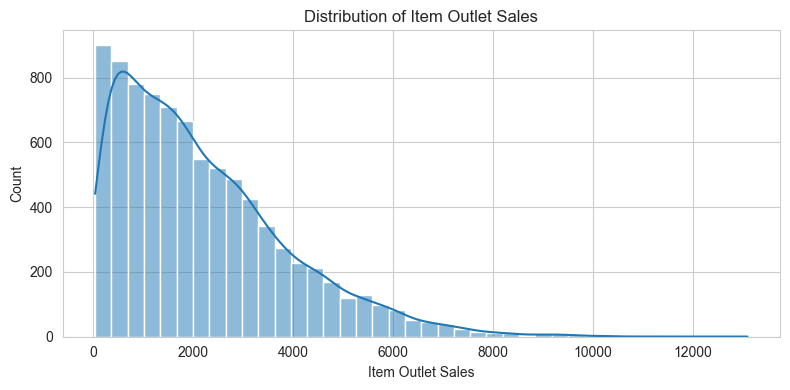

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(train_df["Item_Outlet_Sales"], bins=40, kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Cleaning and Feature Engineering Functions

The same preparation logic is used for both datasets.

For the test set, values are filled using information learned from the training data so that the process stays consistent.

In [8]:
def clean_train_data(df: pd.DataFrame) -> pd.DataFrame:
    clean_df = df.copy()

    clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace({
        "LF": "Low Fat",
        "low fat": "Low Fat",
        "reg": "Regular"
    })

    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
        clean_df.groupby("Item_Identifier")["Item_Weight"].transform("mean")
    )
    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
        clean_df.groupby("Item_Type")["Item_Weight"].transform("mean")
    )

    outlet_size_map = clean_df.groupby("Outlet_Type")["Outlet_Size"].agg(lambda x: x.mode().iloc[0])
    clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(
        clean_df["Outlet_Type"].map(outlet_size_map)
    )

    item_visibility_mean = clean_df.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
    overall_visibility_median = clean_df.loc[clean_df["Item_Visibility"] > 0, "Item_Visibility"].median()
    zero_visibility_mask = clean_df["Item_Visibility"] == 0
    replacement_visibility = item_visibility_mean.mask(item_visibility_mean == 0, overall_visibility_median)
    clean_df.loc[zero_visibility_mask, "Item_Visibility"] = replacement_visibility[zero_visibility_mask]

    clean_df["Item_Category"] = clean_df["Item_Identifier"].str[:2].map({
        "FD": "Food",
        "NC": "Non-Consumable",
        "DR": "Drinks"
    })
    clean_df.loc[clean_df["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"

    clean_df["Outlet_Age"] = 2013 - clean_df["Outlet_Establishment_Year"]
    clean_df["Item_Visibility_Mean"] = clean_df.groupby("Item_Identifier")["Item_Visibility"].transform("mean")
    clean_df["Visibility_Ratio"] = clean_df["Item_Visibility"] / clean_df["Item_Visibility_Mean"]

    return clean_df


def clean_test_data(df: pd.DataFrame, train_reference: pd.DataFrame) -> pd.DataFrame:
    clean_df = df.copy()
    reference_df = train_reference.copy()

    clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace({
        "LF": "Low Fat",
        "low fat": "Low Fat",
        "reg": "Regular"
    })

    item_weight_map = reference_df.groupby("Item_Identifier")["Item_Weight"].mean()
    item_type_weight_map = reference_df.groupby("Item_Type")["Item_Weight"].mean()
    outlet_size_map = reference_df.groupby("Outlet_Type")["Outlet_Size"].agg(lambda x: x.mode().iloc[0])
    item_visibility_map = reference_df.groupby("Item_Identifier")["Item_Visibility"].mean()
    overall_visibility_median = reference_df.loc[reference_df["Item_Visibility"] > 0, "Item_Visibility"].median()

    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(clean_df["Item_Identifier"].map(item_weight_map))
    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(clean_df["Item_Type"].map(item_type_weight_map))

    clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(clean_df["Outlet_Type"].map(outlet_size_map))

    zero_visibility_mask = clean_df["Item_Visibility"] == 0
    replacement_visibility = clean_df["Item_Identifier"].map(item_visibility_map).fillna(overall_visibility_median)
    clean_df.loc[zero_visibility_mask, "Item_Visibility"] = replacement_visibility[zero_visibility_mask]

    clean_df["Item_Category"] = clean_df["Item_Identifier"].str[:2].map({
        "FD": "Food",
        "NC": "Non-Consumable",
        "DR": "Drinks"
    })
    clean_df.loc[clean_df["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"

    clean_df["Outlet_Age"] = 2013 - clean_df["Outlet_Establishment_Year"]
    clean_df["Item_Visibility_Mean"] = clean_df["Item_Identifier"].map(item_visibility_map).fillna(overall_visibility_median)
    clean_df["Visibility_Ratio"] = clean_df["Item_Visibility"] / clean_df["Item_Visibility_Mean"]

    return clean_df

## 5. Apply the Preparation to Train and Test

The training data is cleaned first, and then the same logic is applied to the test data using the training set as reference.

In [9]:
prepared_train = clean_train_data(train_df)
prepared_test = clean_test_data(test_df, prepared_train)

print("Prepared train shape:", prepared_train.shape)
print("Prepared test shape:", prepared_test.shape)

Prepared train shape: (8523, 16)
Prepared test shape: (5681, 15)


In [10]:
print("Prepared train missing values:", int(prepared_train.isna().sum().sum()))
print("Prepared test missing values:", int(prepared_test.isna().sum().sum()))

Prepared train missing values: 0
Prepared test missing values: 0


In [11]:
prepared_train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Item_Category,Outlet_Age,Item_Visibility_Mean,Visibility_Ratio
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,Food,14,0.017387,0.922960
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,Drinks,4,0.019219,1.003057
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,Food,14,0.020145,0.831990
3,FDX07,19.20,Regular,0.015274,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,Food,15,0.020365,0.750000
4,NCD19,8.93,Non-Edible,0.008082,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,Non-Consumable,26,0.012123,0.666667


## 6. Save the Prepared Files

These saved files will be used in the second notebook for modeling and final prediction.

In [12]:
prepared_train.to_csv("prepared_train.csv", index=False)
prepared_test.to_csv("prepared_test.csv", index=False)

print("Saved prepared_train.csv")
print("Saved prepared_test.csv")

Saved prepared_train.csv
Saved prepared_test.csv
